# Colorectal Cancer Data Cleaning and Exploration

This notebook cleans the colorectal cancer dataset and performs one hypothesis test with a supporting plot.

**Dataset source:** [Colorectal Cancer Global Dataset & Predictions (Kaggle)](https://www.kaggle.com/datasets/ankushpanday2/colorectal-cancer-global-dataset-and-predictions)

# Section 1: Data Preprocessing and Data Cleaning

This section imports the CSV into a pandas DataFrame, removes extra whitespace, checks numeric values, handles duplicates and missing values, and converts data types.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1.1 Import and inspect the raw data

`skipinitialspace=True` removes spaces immediately following commas. The next cleaning step also strips trailing spaces from headers and text values.

In [2]:
data_path = "colorectal_cancer_dataset.csv"
raw_df = pd.read_csv(data_path, skipinitialspace=True)

print(f"Raw dataset: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns")
display(raw_df.head())

# Check data types, missing values, and unique values before cleaning.
raw_profile = pd.DataFrame({
    "Data_Type": raw_df.dtypes.astype(str),
    "Missing_Count": raw_df.isna().sum(),
    "Missing_Rate": raw_df.isna().mean(),
    "Unique_Values": raw_df.nunique(dropna=False),
})
raw_profile

Raw dataset: 167,497 rows and 28 columns


,Patient_ID,Country,Age,Gender,Cancer_Stage,Tumor_Size_mm,Family_History,Smoking_History,Alcohol_Consumption,Obesity_BMI,Diet_Risk,Physical_Activity,Diabetes,Inflammatory_Bowel_Disease,Genetic_Mutation,Screening_History,Early_Detection,Treatment_Type,Survival_5_years,Mortality,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K,Urban_or_Rural,Economic_Classification,Healthcare_Access,Insurance_Status,Survival_Prediction
0,1,UK,77,M,Localized,69,No,No,Yes,Overweight,Low,Low,No,No,No,Regular,Yes,Combination,Yes,No,54413,50,5,Urban,Developed,Moderate,Insured,Yes
1,2,UK,59,M,Localized,33,No,No,No,Overweight,Moderate,Low,No,No,No,Regular,No,Chemotherapy,Yes,No,76553,37,25,Urban,Developing,High,Uninsured,Yes
2,3,Japan,66,M,Regional,17,No,Yes,No,Normal,Low,Low,No,Yes,No,Irregular,No,Chemotherapy,Yes,No,62805,54,27,Urban,Developed,Moderate,Uninsured,No
3,4,USA,83,M,Regional,14,No,No,No,Obese,High,Low,No,No,No,Regular,No,Surgery,Yes,No,89393,45,11,Urban,Developed,Moderate,Insured,Yes
4,5,France,66,M,Localized,34,No,Yes,No,Normal,Low,Moderate,No,Yes,No,Never,Yes,Surgery,Yes,No,66425,15,27,Urban,Developing,High,Insured,Yes


,Data_Type,Missing_Count,Missing_Rate,Unique_Values
Patient_ID,int64,0,0.0,167497
Country,str,0,0.0,16
Age,int64,0,0.0,60
Gender,str,0,0.0,2
Cancer_Stage,str,0,0.0,3
Tumor_Size_mm,int64,0,0.0,75
Family_History,str,0,0.0,2
Smoking_History,str,0,0.0,2
Alcohol_Consumption,str,0,0.0,2
Obesity_BMI,str,0,0.0,3


## 1.2 Clean, validate, and transform

The main data-quality issue is padded whitespace in column names and categorical values. The code also checks required numeric ranges, removes duplicate rows and patient IDs, fills any missing values, converts Yes/No fields to binary integers, and stores repeated labels as categorical data. Rows where the mortality rate exceeds the incidence rate are flagged and retained because the CSV does not document the rates' time windows; changing them would require source clarification.

In [3]:
df = raw_df.copy()

# Standardize column names and categorical text.
df.columns = df.columns.str.strip()
text_columns = df.select_dtypes(include=["str", "object"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()
df[text_columns] = df[text_columns].replace("", pd.NA)

# Parse numeric columns and replace impossible values with missing values.
numeric_columns = [
    "Patient_ID", "Age", "Tumor_Size_mm", "Healthcare_Costs",
    "Incidence_Rate_per_100K", "Mortality_Rate_per_100K"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

valid_ranges = {
    "Age": (0, 120),
    "Tumor_Size_mm": (0, np.inf),
    "Healthcare_Costs": (0, np.inf),
    "Incidence_Rate_per_100K": (0, np.inf),
    "Mortality_Rate_per_100K": (0, np.inf),
}
invalid_numeric_values = 0
for column, (lower, upper) in valid_ranges.items():
    invalid = ~df[column].between(lower, upper, inclusive="both") & df[column].notna()
    invalid_numeric_values += int(invalid.sum())
    df.loc[invalid, column] = np.nan

# Count rows that may need source verification. Do not change them automatically.
rate_order_flags = int(
    (df["Mortality_Rate_per_100K"] > df["Incidence_Rate_per_100K"]).sum()
)

# Count and remove duplicate records. Patient_ID should uniquely identify a row.
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
duplicate_patient_ids = int(df["Patient_ID"].duplicated().sum())
df = df.drop_duplicates(subset="Patient_ID", keep="first").copy()

# Patient_ID is required; remove rows where it is missing.
missing_patient_ids = int(df["Patient_ID"].isna().sum())
df = df.dropna(subset=["Patient_ID"]).copy()
df["Patient_ID"] = df["Patient_ID"].astype("int64")

missing_before_imputation = int(df.isna().sum().sum())
measurement_columns = [column for column in numeric_columns if column != "Patient_ID"]
for column in measurement_columns:
    df[column] = df[column].fillna(df[column].median())
df[measurement_columns] = df[measurement_columns].round().astype("int64")

text_columns = df.select_dtypes(include=["str", "object"]).columns
for column in text_columns:
    if df[column].isna().any():
        df[column] = df[column].fillna(df[column].mode().iloc[0])

# Convert Yes/No fields to 1/0 and remaining text fields to category dtype.
binary_columns = [
    "Family_History", "Smoking_History", "Alcohol_Consumption",
    "Diabetes", "Inflammatory_Bowel_Disease", "Genetic_Mutation",
    "Early_Detection", "Survival_5_years", "Mortality",
    "Survival_Prediction"
]
for column in binary_columns:
    df[column] = df[column].map({"No": 0, "Yes": 1}).astype("int8")

categorical_columns = df.select_dtypes(include=["str", "object"]).columns
for column in categorical_columns:
    df[column] = df[column].astype("category")

df = df.reset_index(drop=True)

In [4]:
quality_report = pd.Series({
    "Raw rows": len(raw_df),
    "Clean rows": len(df),
    "Exact duplicate rows found": exact_duplicates,
    "Duplicate patient IDs found": duplicate_patient_ids,
    "Missing patient IDs removed": missing_patient_ids,
    "Invalid numeric values found": invalid_numeric_values,
    "Rate-order flags retained for review": rate_order_flags,
    "Missing values before imputation": missing_before_imputation,
    "Missing values after cleaning": int(df.isna().sum().sum()),
})

display(quality_report.to_frame("Count"))
print(f"Patient IDs unique: {df['Patient_ID'].is_unique}")
print(f"Final dataset: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.info()

,Count
Raw rows,167497
Clean rows,167497
Exact duplicate rows found,0
Duplicate patient IDs found,0
Missing patient IDs removed,0
Invalid numeric values found,0
Rate-order flags retained for review,25449
Missing values before imputation,0
Missing values after cleaning,0


Patient IDs unique: True
Final dataset: 167,497 rows and 28 columns
<class 'pandas.DataFrame'>
RangeIndex: 167497 entries, 0 to 167496
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype   
---  ------                      --------------   -----   
 0   Patient_ID                  167497 non-null  int64   
 1   Country                     167497 non-null  category
 2   Age                         167497 non-null  int64   
 3   Gender                      167497 non-null  category
 4   Cancer_Stage                167497 non-null  category
 5   Tumor_Size_mm               167497 non-null  int64   
 6   Family_History              167497 non-null  int8    
 7   Smoking_History             167497 non-null  int8    
 8   Alcohol_Consumption         167497 non-null  int8    
 9   Obesity_BMI                 167497 non-null  category
 10  Diet_Risk                   167497 non-null  category
 11  Physical_Activity           167497 non-null  category
 12  D

# Section 2: Basic Data Exploration and Summary Statistics

This section contributes one conclusion for the team project. It uses a chi-square test of independence and one supporting plot.

## 2.1 Dataset overview

One row represents one patient record, identified by `Patient_ID`. The cleaned dataset contains 167,497 entries and 28 columns. The CSV has no sampling or date fields, so the results describe these records only. `Survival_Prediction` looks like an output variable and could leak the answer if it were used to predict `Survival_5_years`.

In [5]:
print(f"Entries: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Non-ID variables: {df.shape[1] - 1}")

summary_columns = [
    "Age", "Tumor_Size_mm", "Healthcare_Costs",
    "Incidence_Rate_per_100K", "Mortality_Rate_per_100K"
]
df[summary_columns].describe().round(2)

Entries: 167,497
Columns: 28
Non-ID variables: 27


,Age,Tumor_Size_mm,Healthcare_Costs,Incidence_Rate_per_100K,Mortality_Rate_per_100K
count,167497.00,167497.00,167497.00,167497.00,167497.00
mean,69.20,42.01,72452.17,34.53,17.02
std,11.87,21.67,27402.78,14.45,7.21
min,30.00,5.00,25000.00,10.00,5.00
25%,59.00,23.00,48760.00,22.00,11.00
50%,69.00,42.00,72344.00,35.00,17.00
75%,79.00,61.00,96227.00,47.00,23.00
max,89.00,79.00,119999.00,59.00,29.00


## 2.2 Conclusion 1: Early detection and five-year survival

**Method: chi-square test of independence**

- Null hypothesis ($H_0$): early-detection status and five-year survival are independent.
- Alternative hypothesis ($H_A$): early-detection status and five-year survival are associated.
- Significance level: $\alpha = 0.05$.

Both variables are categorical, so a chi-square test of independence is appropriate. Expected cell counts should be at least 5. The test statistic is compared with the chi-square critical value for $\alpha=0.05$ and one degree of freedom.

In [6]:
observed = pd.crosstab(df["Early_Detection"], df["Survival_5_years"])
observed = observed.reindex(index=[0, 1], columns=[0, 1])
observed.index = ["No early detection", "Early detection"]
observed.columns = ["Did not survive", "Survived"]

grand_total = observed.sum().sum()
expected = observed.copy().astype(float)
for row in observed.index:
    for column in observed.columns:
        expected.loc[row, column] = (
            observed.loc[row].sum() * observed[column].sum() / grand_total
        )

chi_square = (((observed - expected) ** 2) / expected).sum().sum()
degrees_of_freedom = 1
critical_value = 3.841  # Chi-square table value for alpha = 0.05 and df = 1
survival_rates = observed["Survived"] / observed.sum(axis=1)

if chi_square > critical_value:
    decision = "Reject the null hypothesis."
else:
    decision = "Fail to reject the null hypothesis."

print("Observed frequencies:")
display(observed)
print("Expected frequencies under H0:")
display(expected.round(2))
print(f"Smallest expected count: {expected.to_numpy().min():,.2f}")
print(f"Chi-square statistic: {chi_square:.3f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"Critical value: {critical_value:.3f}")
print(decision)

Observed frequencies:


,Did not survive,Survived
No early detection,26880,40357
Early detection,40230,60030


Expected frequencies under H0:


,Did not survive,Survived
No early detection,26939.44,40297.56
Early detection,40170.56,60089.44


Smallest expected count: 26,939.44
Chi-square statistic: 0.366
Degrees of freedom: 1
Critical value: 3.841
Fail to reject the null hypothesis.


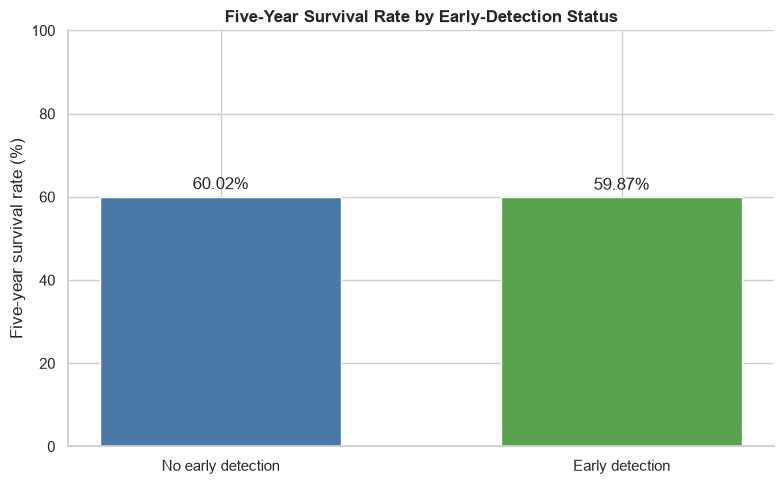

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    survival_rates.index,
    survival_rates * 100,
    color=["#4C78A8", "#59A14F"],
    width=0.6,
)

ax.set_title("Five-Year Survival Rate by Early-Detection Status", weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Five-year survival rate (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, labels=[f"{rate:.2f}%" for rate in survival_rates * 100], padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### Conclusion

Five-year survival was 60.02% without early detection and 59.87% with early detection. The difference was 0.15 percentage points. All expected counts were greater than 5. The chi-square statistic was 0.366, which is below the critical value of 3.841. Therefore, we fail to reject the null hypothesis. The data do not show a significant association between early-detection status and five-year survival. This observational result does not establish cause and effect.

## 2.3 Conclusion 2: [Add title]

**Method:** [Add a statistical method that differs from Conclusion 1]

[State the question being examined and explain why the method is appropriate.]

[Add the calculation in a code cell and include one supporting plot.]

### Conclusion

[Summarize the result and explain what it means for this dataset.]

## 2.4 Conclusion 3: [Add title]

**Method:** [Add a statistical method that differs from Conclusions 1 and 2]

[State the question being examined and explain why the method is appropriate.]

[Add the calculation in a code cell and include one supporting plot.]

### Conclusion

[Summarize the result and explain what it means for this dataset.]